# Из файлов в корпус: извлечение и очистка текстов

На прошлых занятиях мы скачивали страницы и собирали данные с сайтов. Вместе с HTML краулер может получить документы Word, презентации, PDF и картинки. Теперь нужно достать из них текст и решить, что оставить для анализа.

Сегодня соберём небольшую русскоязычную коллекцию: извлечём содержимое файлов, уберём разметку и лишние пробелы, определим язык и найдём повторы.

## Импорты

Ставим все необходимые библиотеки

In [1]:
%pip install beautifulsoup4 python-docx python-pptx pypdf pandas rapidfuzz langid Pillow wget -q

Note: you may need to restart the kernel to use updated packages.


Импорты

In [2]:
import re
import unicodedata
from html import unescape
import os
import requests
from urllib.parse import urljoin

import wget
import pandas as pd
from bs4 import BeautifulSoup
from docx import Document
from docx.table import Table
from docx.text.paragraph import Paragraph
from pptx import Presentation
from pypdf import PdfReader
from rapidfuzz import fuzz
from IPython.display import display, Image

pd.set_option('display.max_colwidth', 100)

Скачаем данные с гитхаба

In [3]:
os.makedirs('data', exist_ok=True)

url = 'https://api.github.com/repos/hse-ling-python/hse-ling_26-27/contents/files/bad_data?ref=main'
response = requests.get(url)
response.raise_for_status()

for file in response.json():
    if file['type'] == 'file':
        path = os.path.join('data', file['name'])
        wget.download(file['download_url'], out=path)

Что есть в данных

In [4]:
os.listdir('data')

['eurotext.png',
 'article.html',
 'notice_scan.png',
 'corpus_slides.pptx',
 'frogs_report.pdf',
 'frogs_report.docx',
 'corpus_notes.docx',
 'reading.pdf',
 'frogs_slides.pptx',
 'scan.pdf']

| Файл | Для чего понадобится |
| --- | --- |
| `corpus_notes.docx` | Абзацы, таблица и колонтитулы Word |
| `corpus_slides.pptx` | Текстовые блоки на двух слайдах |
| `reading.pdf` | Текстовый слой и порядок чтения двух колонок |
| `scan.pdf`, `notice_scan.png` | Один и тот же текст как изображение |
| `article.html` | Статья с меню, рекламой и HTML-сущностями |
| `frogs_report.pdf`, `frogs_report.docx`, `frogs_slides.pptx`| Данные для практики |

## 1. Извлекаем текст из файлов

Расширение файла подсказывает, какой инструмент попробовать. Но одинаковое расширение не гарантирует одинакового устройства содержимого: например, PDF может хранить текст или только картинку страницы.

### DOCX: абзацы и таблицы

Для файлов `.docx` используем `python-docx`. Пакет устанавливается под этим названием, но импортируется как `docx`. Он не читает старые файлы `.doc`: их сначала придётся конвертировать.

Начнём с абзацев основного текста. `paragraph.text` возвращает текст абзаца без его оформления.

In [5]:
document = Document('data/corpus_notes.docx')

for paragraph in document.paragraphs:
    if paragraph.text.strip():
        print(paragraph.text)

Сбор текстового корпуса
Студенты собирают корпус русских текстов. В коллекцию входят новости, объявления и небольшие статьи. Для каждого текста сохраняют источник и проверяют качество извлечения.
Состав коллекции
В таблице указано, сколько документов каждой группы подготовили к занятию. Сначала читают документы, затем сверяют числа в таблице.
Проверка результата
Таблица находится между абзацами. Если сначала собрать все абзацы, а затем все таблицы, порядок частей документа изменится.


Откройте документ в текстовом редакторе. Между абзацами есть таблица с числами, но в выводе её нет: `document.paragraphs` не включает текст таблиц. Достанем его отдельно. `table.rows` содержит строки таблицы, а `row.cells` - ячейки строки.

In [6]:
for table in document.tables:
    for row in table.rows:
        print([cell.text for cell in row.cells])

['Группа документов', 'Количество']
['Новости', '4']
['Объявления', '3']
['Статьи', '5']


Если собрать сначала все абзацы, а потом все таблицы, их исходный порядок потеряется. В `python-docx` есть метод `iter_inner_content()`: он по очереди возвращает абзацы и таблицы основного текста. Проверим тип блока через `isinstance()` и сохраним его номер.

In [7]:
docx_fragments = []
for number, block in enumerate(document.iter_inner_content(), start=1):
    if isinstance(block, Paragraph):
        text = block.text
        block_type = 'paragraph'
    elif isinstance(block, Table):
        text = '\n'.join(
            '\t'.join(cell.text for cell in row.cells)
            for row in block.rows
        )
        block_type = 'table'
    if text.strip():
        docx_fragments.append({
            'source': 'corpus_notes.docx',
            'block': number,
            'block_type': block_type,
            'raw_text': text,
        })

pd.DataFrame(docx_fragments)

,source,block,block_type,raw_text
0,corpus_notes.docx,1,paragraph,Сбор текстового корпуса
1,corpus_notes.docx,2,paragraph,"Студенты собирают корпус русских текстов. В коллекцию входят новости, объявления и небольшие ста..."
2,corpus_notes.docx,3,paragraph,Состав коллекции
3,corpus_notes.docx,4,paragraph,"В таблице указано, сколько документов каждой группы подготовили к занятию. Сначала читают докуме..."
4,corpus_notes.docx,5,table,Группа документов\tКоличество\nНовости\t4\nОбъявления\t3\nСтатьи\t5
5,corpus_notes.docx,6,paragraph,Проверка результата
6,corpus_notes.docx,7,paragraph,"Таблица находится между абзацами. Если сначала собрать все абзацы, а затем все таблицы, порядок ..."


Колонтитулы в этот список не попали: `iter_inner_content()` обходит только абзацы и таблицы основного текста. Найдите колонтитулы в учебном файле. Для них, как и для комментариев, текстовых полей и вложенных таблиц, понадобится отдельная обработка.

Подробнее: [объекты Document и iter_inner_content](https://python-docx.readthedocs.io/en/latest/api/document.html).

### PPTX: текст на слайдах

Презентацию `.pptx` читаем через `python-pptx`. В ней есть слайды, а на слайдах - объекты `shape`: текстовые блоки, картинки, таблицы и другие элементы. Свойство `has_text_frame` сообщает, есть ли у объекта текстовое поле. Сам текст берём через `.text`.

Номер объекта в файле может отличаться от порядка чтения слайда глазами. Текст внутри картинки таким способом не извлечётся. Здесь читаем только текстовые поля верхнего уровня; группы объектов и таблицы нужно обходить отдельно.

In [8]:
slides = Presentation('data/corpus_slides.pptx')
pptx_fragments = []

for slide_number, slide in enumerate(slides.slides):
    for shape_number, shape in enumerate(slide.shapes):
        if shape.has_text_frame and shape.text.strip():
            pptx_fragments.append({
                'source': 'corpus_slides.pptx',
                'slide': slide_number,
                'shape': shape_number,
                'raw_text': shape.text,
            })

pd.DataFrame(pptx_fragments)

,source,slide,shape,raw_text
0,corpus_slides.pptx,0,0,Сбор текстового корпуса
1,corpus_slides.pptx,0,1,"Студенты собирают корпус русских текстов. В коллекцию входят новости, объявления и небольшие ста..."
2,corpus_slides.pptx,0,2,Для каждого текста сохраняют источник и проверяют качество извлечения.
3,corpus_slides.pptx,1,0,Проверка извлечённого текста
4,corpus_slides.pptx,1,1,Один слайд может содержать несколько отдельных текстовых блоков.
5,corpus_slides.pptx,1,2,Имя файла и номер слайда помогают вернуться к оригиналу.
6,corpus_slides.pptx,1,3,Порядок объектов в файле стоит сверять с визуальным порядком чтения.


[Подробнее о текстовых полях python-pptx](https://python-pptx.readthedocs.io/en/stable/user/text.html). Старые `.ppt` сначала конвертируют в современный формат.

### PDF: текстовый слой и порядок чтения

**Текстовый слой** - текстовые объекты внутри PDF. Библиотека `pypdf` умеет читать их, но не распознаёт буквы на изображении.

В PDF расположение текста задаётся на странице. При извлечении приходится восстанавливать пробелы, строки и последовательность фрагментов. Поэтому результат может содержать колонтитулы, номера страниц, разорванные слова или перепутанные колонки.

In [9]:
reader = PdfReader('data/reading.pdf')
pdf_fragments = []

for page_number, page in enumerate(reader.pages):
    text = page.extract_text() or ''
    pdf_fragments.append({
        'source': 'reading.pdf',
        'page': page_number,
        'raw_text': text,
    })
    print('Страница', page_number, '- символов:', len(text))

Страница 0 - символов: 375
Страница 1 - символов: 643


Первая страница, где текст обычный

In [10]:
print(pdf_fragments[0]['raw_text'])

Практикум по работе с текстами
Материалы для корпуса
Студенты собирают корпус русских текстов. В коллекцию входят новости, объявления и
небольшие статьи. Для каждого текста сохраняют источник и проверяют качество
извлечения.
Один документ может содержать несколько абзацев. Номер страницы помогает
вернуться к оригиналу и проверить результат извлечения.
Материалы семинара
1



И вторая, где в две колонки. Обратите внимание, что тут чтение текста уже работает сильно хуже

In [11]:
print(pdf_fragments[1]['raw_text'])

Практикум по работе с текстами
Страница с двумя колонками
ЛЕВАЯ КОЛОНКА. Начало заметки. При
извлечении текста важно сохранить
последовательность предложений.
ПРАВАЯ КОЛОНКА. Продолжение заметки.
Здесь описаны способы проверки
полученного текста.
Вторая часть левой колонки продолжает ту
же мысль. Визуальная близость строк не
всегда задает порядок чтения.
Сравните начало и конец каждой колонки с
оригиналом. Обратите внимание на
заголовок и повторяющийся колонтитул.
Конец левой колонки. После этого читатель
переходит к началу правой колонки.
Конец правой колонки. Сохраните номер
страницы рядом с извлеченным текстом.
Материалы семинара
2



Откройте вторую страницу `reading.pdf`: слева начало заметки, справа продолжение. Найдите в выводе место, где текст перескакивает между колонками.

Пустой результат тоже нужно сверять с оригиналом: помимо сканов, так могут проявляться проблемы шрифтов и другие особенности PDF.

[Почему извлечение текста из PDF бывает сложным](https://pypdf.readthedocs.io/en/stable/user/extract-text.html).

### Скан и картинка: OCR

В `scan.pdf` лежит одна картинка, без текстового слоя. Та же картинка сохранена отдельно как `notice_scan.png`. Сравним изображение и результат обычного извлечения.

Извлечение из скана: ''


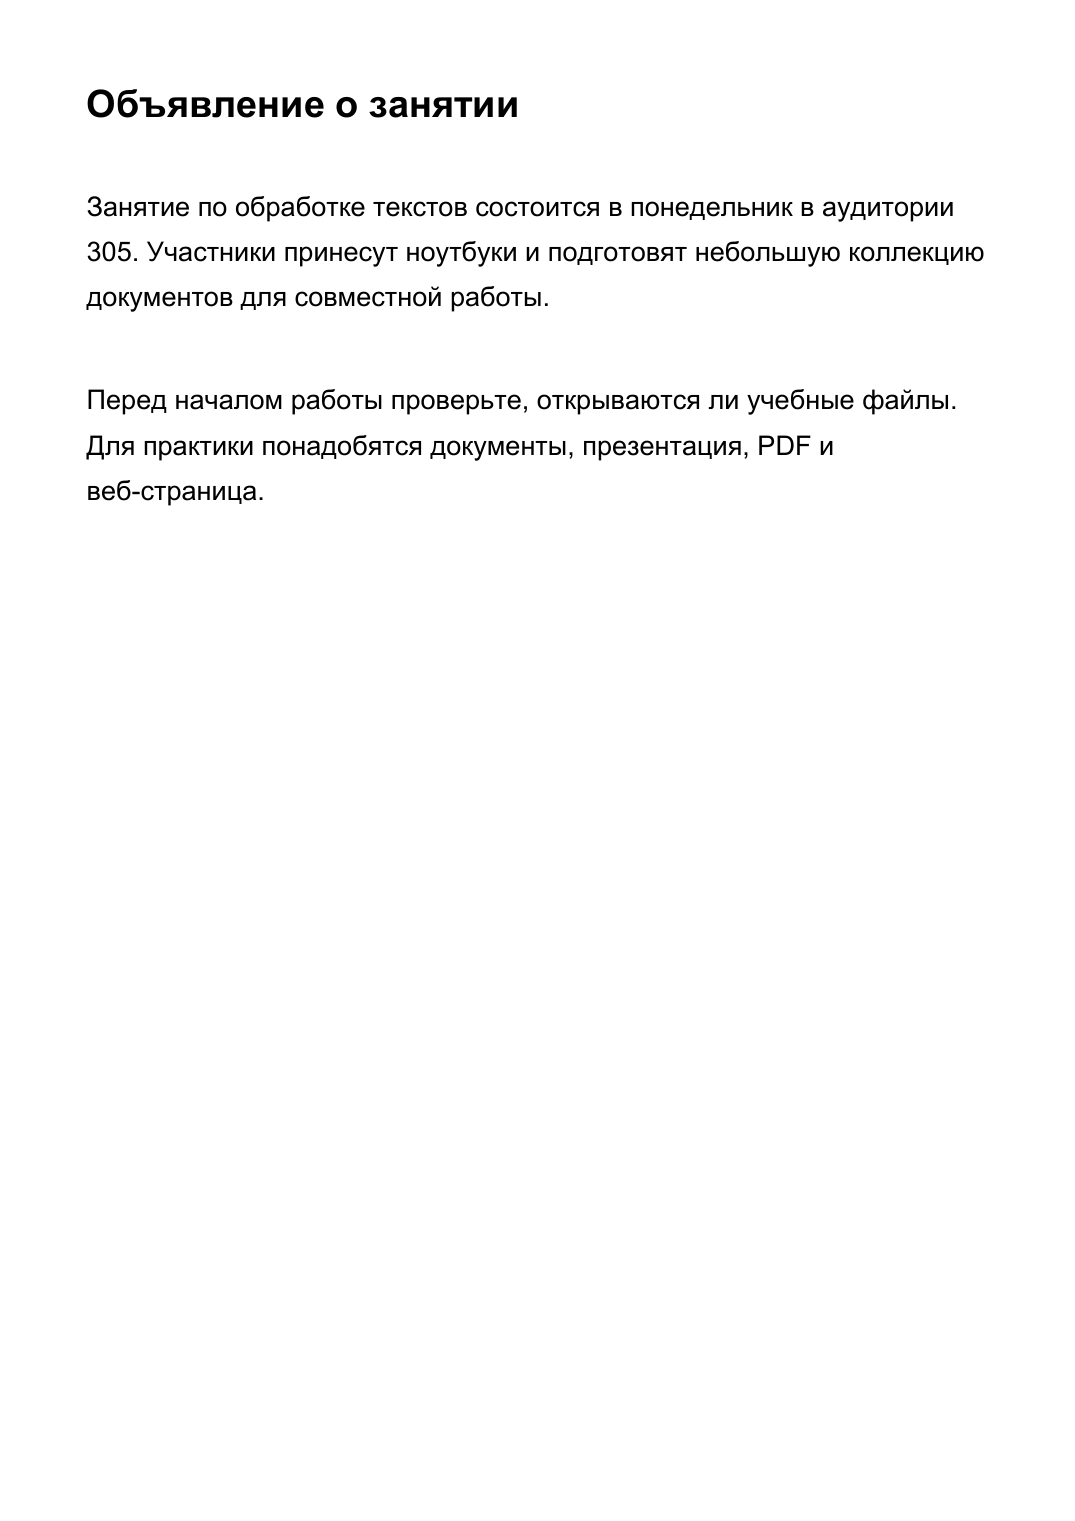

In [12]:
scan_reader = PdfReader('data/scan.pdf')
scan_text = scan_reader.pages[0].extract_text() or ''
print('Извлечение из скана:', repr(scan_text))
display(Image(filename=str('data/notice_scan.png'), width=420))

**OCR (Optical Character Recognition)** - распознавание текста на изображении. Например, программа Tesseract ищет буквы на картинке и возвращает текст. Он тоже требует проверки: могут потеряться знаки препинания или перепутаться похожие символы.

`pytesseract` - Python-обёртка над Tesseract. Установка обёртки не устанавливает саму программу. Для необязательного запуска поставьте [Tesseract](https://tesseract-ocr.github.io/tessdoc/Installation.html), языковые данные `rus` и `eng`, затем `%pip install pytesseract`. Изображение открываем библиотекой Pillow, которая импортируется как `PIL`.

Тессеракт ставится достаточно долго и иногда больно, так что можете просто посмотреть тут, а устанавливать в случае необходимости. В практике сегодня его не будет.

In [13]:
%pip install pytesseract -q

Note: you may need to restart the kernel to use updated packages.


In [14]:
import pytesseract
from PIL import Image as PILImage

In [15]:
languages = pytesseract.get_languages(config='')
if {'rus', 'eng'}.issubset(languages):
    with PILImage.open('data/notice_scan.png') as image:
        ocr_text = pytesseract.image_to_string(image, lang='rus+eng')
    print(ocr_text)

Объявление о занятии

Занятие по обработке текстов состоится в понедельник в аудитории
305. Участники принесут ноутбуки и подготовят небольшую коллекцию

документов для совместной работы.

Перед началом работы проверьте, открываются ли учебные файлы.
Для практики понадобятся документы, презентация, PDF и

веб-страница.



### Как выгрузить картинку с сайта

Для того, чтобы выгрузить картинку с сайта, надо найти в html разметке ссылку на нее. Иногда она скрыта в js или как-то еще, тогда придется помучиться. Но мы сегодня посмотрим на простой пример, когда в html есть конкретная ссылка на изображение.

Посмотрим [сайт тессеракта](https://tesseract-ocr.github.io/tessdoc/Command-Line-Usage.html#:~:text=eng%20%2D%2Dpsm%203-,Following,-examples%20use%20this), где есть популярная картинка для теста OCR.

В коде сайта это просто абзац с картинкой внутри

```html
<p>
    <img src="/tessdoc/images/eurotext.png" alt="eurotext.png">
</p>
```
Составим запрос и найдем на сайте ссылку на картинку:

In [16]:
tes_path = 'https://tesseract-ocr.github.io/tessdoc/Command-Line-Usage.html'
tes_page = requests.get(tes_path)
tes_page.raise_for_status()

tes_soup = BeautifulSoup(tes_page.text, 'html.parser')
img_url = urljoin(
    tes_page.url,
    tes_soup.select_one('img[alt="eurotext.png"]').get('src')
)
img_url

'https://tesseract-ocr.github.io/tessdoc/images/eurotext.png'

Теперь выгрузим эту картинку и посмотрим на нее. Обратите внимание, что здесь нам нужно поле `content`, а не `text`, так как картинка - это набор байт, а не просто текст. По той же причине мы используем `wb` вместо простого `w` у записи файла, так как это сокращение от `write binary` и позволяет записывать контент в виде байтов.

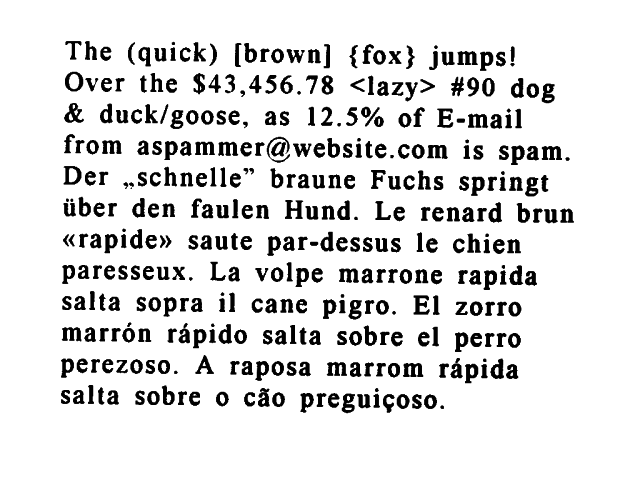

In [17]:
response = requests.get(img_url)
response.raise_for_status()
with open('data/eurotext.png', 'wb') as file:
    file.write(response.content)

image = PILImage.open('data/eurotext.png')
display(image)

Заодно попробуем распознать текст на картинке, раз уж он на ней есть.

In [18]:
ocr_text = pytesseract.image_to_string(image, lang='rus+eng')
print(ocr_text)

The (quick) [brown] {fox} jumps!
Over the $43,456.78 <lazy> #90 dog
& duck/goose, as 12.5% of E-mail
from aspammer@website.com is spam.
Der ,.schnelle” braune Fuchs springt
tiber den faulen Hund. Le renard brun
«rapide» saute par-dessus le chien
paresseux. La volpe marrone rapida
salta sopra il cane pigro. El zorro
marron rapido salta sobre el perro
perezoso. A raposa marrom rapida
salta sobre о сёо preguicoso.



## 2. Очищаем HTML от разметки и служебных блоков

После краулинга у нас часто остаётся HTML страницы. Когда вы краулите один сайт, можно сделать краулер аккуратным и доставать текст сразу в нужном виде, как мы делали на прошлой паре. Но иногда вам нужно выгрузить десятки сайтов, и вы часто уже не очень хотите писать отдельную логику обработки для каждого. Здесь мы переходим к более грубому решению - извлечению всего текстового контента. Вот только такой контент будет грязным: даже если тегов больше нет, в строке могут остаться меню, реклама и рекомендации.

In [19]:
with open('data/article.html', encoding='utf-8') as f:
    html_text = f.read()
soup = BeautifulSoup(html_text, 'html.parser')
print(soup.get_text(' ', strip=True))

Новости практикума Home | News | About | Subscribe Коллекция текстов для семинара Редакция практикума, 16 ноября 2026 года Студенты собирают корпус русских текстов. В коллекцию входят новости, объявления и небольшие статьи. Реклама: подпишитесь на рассылку! В архиве уже 10 000 слов. Для каждого текста сохраняют источник и проверяют качество извлечения. На занятии сравним PDF & DOCX, а затем очистим тексты. Читайте также: как выбрать ноутбук. Contacts | Privacy | All rights reserved


В выводе есть английское меню и реклама. Если сразу определять язык всей страницы, служебные блоки могут повлиять на результат. Найдём контейнер `.article-body` и удалим рекламный блок через `decompose()`. Этот метод удаляет элемент вместе с содержимым из дерева HTML.

Чтобы сохранить абзацы, сначала находим отдельные теги `p`, затем получаем текст каждого.

In [20]:
article_body = soup.select_one('.article-body')
if article_body is None:
    raise ValueError('Не найден контейнер статьи: проверьте разметку.')

for element in article_body.select('.advert, script, style'):
    element.decompose()

paragraphs = [p.get_text(' ', strip=True) for p in article_body.find_all('p')]
article_text = '\n\n'.join(paragraphs)
print(article_text)

Студенты собирают корпус русских текстов. В коллекцию входят новости, объявления и небольшие статьи.

В архиве уже 10 000 слов. Для каждого текста сохраняют источник и проверяют качество извлечения.

На занятии сравним PDF & DOCX, а затем очистим тексты.


### HTML-сущности

**HTML-сущность** - запись символа через специальное обозначение: `&amp;` означает `&`, `&nbsp;` - неразрывный пробел. BeautifulSoup уже декодирует их при разборе HTML. Пробел при этом остаётся особым символом, его нормализуем позже.

Если у нас строка с сущностями, но без HTML-тегов, можно один раз применить `html.unescape()`. Не нужно повторять декодирование до тех пор, пока строка меняется: запись `&amp;lt;` может обозначать буквальный текст `&lt;`, а не знак `<`.

In [21]:
escaped_text = 'PDF &amp; DOCX: 10&nbsp;000 слов'
print(repr(unescape(escaped_text)))
print(unescape('&amp;lt;'))  # Один уровень декодирования.

'PDF & DOCX: 10\xa0000 слов'
&lt;


## 3. Очищаем грязный текст

### Как увидеть невидимые символы

Две строки могут выглядеть одинаково, но содержать разные символы. `repr()` показывает служебные символы в форме, удобной для проверки. Например, `\t` - табуляция, `\n` - перевод строки, `\xa0` - неразрывный пробел.

**Unicode** - система, которая задаёт коды символов разных письменностей и специальных знаков. `ord()` возвращает код одного символа, а `unicodedata.name()` - его название. Запись `U+00A0` обозначает код в шестнадцатеричной системе.

In [22]:
dirty = 'В архиве 10\u202f000 слов. Источник\u00a0сохранён. Иссле\u00adдование продолжается.'
print(dirty)
print(repr(dirty))

for char in dict.fromkeys(dirty):
    if char.isspace() or unicodedata.category(char) == 'Cf':
        print(repr(char), f'U+{ord(char):04X}', unicodedata.name(char, 'без названия'))

В архиве 10 000 слов. Источник сохранён. Иссле­дование продолжается.
'В архиве 10\u202f000 слов. Источник\xa0сохранён. Иссле\xadдование продолжается.'
' ' U+0020 SPACE
'\u202f' U+202F NARROW NO-BREAK SPACE
'\xa0' U+00A0 NO-BREAK SPACE
'\xad' U+00AD SOFT HYPHEN


| Символ | Что с ним сделаем в этом занятии |
| --- | --- |
| `\u00a0`, неразрывный пробел | Заменим обычным пробелом |
| `\u202f`, узкий неразрывный пробел | Заменим обычным пробелом |
| `\t`, табуляция | Заменим пробелом в обычном тексте |
| `\u00ad`, мягкий перенос | Удалим знак возможного переноса слова |
| `\r\n` и `\r`, окончания строк | Приведём к `\n` |

Эти решения относятся к обычному тексту. В таблице табуляция может разделять ячейки, поэтому таблицу сначала нужно сохранить как структуру. Мягкий перенос отличается от видимого дефиса в слове `кто-то`.

In [23]:
print(repr(dirty.replace('\u00a0', ' ').replace('\u202f', ' ').replace('\u00ad', '')))

'В архиве 10 000 слов. Источник сохранён. Исследование продолжается.'


`' '.join(text.split())` удобно схлопывает все пробельные символы, но вместе с ними убирает границы абзацев. Регулярное выражение `\s+` тоже захватывает переводы строк. Для нашей коллекции сохраним одиночные переводы строк и одну пустую строку между абзацами.

При извлечении PDF одиночный перевод строки может появиться посреди предложения. В стихотворении тот же символ задаёт структуру текста. Поэтому перед удалением переносов посмотрим, откуда они взялись. 

In [24]:
two_paragraphs = 'Первый абзац.\n\nВторой абзац.'
print(two_paragraphs)
print(' '.join(two_paragraphs.split()))

Первый абзац.

Второй абзац.
Первый абзац. Второй абзац.


### Нормализация Unicode

Некоторые символы можно записать по-разному. Например, `й` бывает готовым символом или сочетанием `и` и отдельного надстрочного знака. Визуально слова одинаковы, а сравнение строк даёт разные результаты.

**Нормализация NFC** приводит такие канонически эквивалентные записи к общей форме. Она не делает одинаковыми `ё` и `е`, не меняет регистр и не заменяет латинскую `a` на кириллическую `а`.

In [25]:
word_a = 'май'
word_b = 'маи\u0306'
print(word_a, word_b)
print('До NFC:', word_a == word_b, len(word_a), len(word_b))
print('После NFC:', unicodedata.normalize('NFC', word_a) == unicodedata.normalize('NFC', word_b))

print('Латиница и кириллица:', 'a' == 'а')
print('Коды:', ord('a'), ord('а'))

май май
До NFC: False 3 4
После NFC: True
Латиница и кириллица: False
Коды: 97 1072


Ниже функция для очистки текста от всяких подозрительных символов. Она принимает **уже извлечённый** текст: HTML и сущности обрабатываются до неё.

In [26]:
def clean_text(text):
    text = unicodedata.normalize('NFC', text)
    text = text.replace('\r\n', '\n').replace('\r', '\n')
    text = text.replace('\u00a0', ' ').replace('\u202f', ' ')
    text = text.replace('\u00ad', '')
    lines = [re.sub(r'[ \t]+', ' ', line).strip() for line in text.split('\n')]
    text = '\n'.join(lines)
    text = re.sub(r'\n{3,}', '\n\n', text)
    return text.strip()

Попробуем на тексте статьи. Через `repr()` видно, что особые пробелы заменились обычными, а границы абзацев остались.

In [27]:
cleaned_article_text = clean_text(article_text)

print('До:', repr(article_text))
print('После:', repr(cleaned_article_text))

До: 'Студенты собирают корпус русских текстов. В коллекцию входят новости, объявления и небольшие статьи.\n\nВ архиве уже 10\u202f000 слов. Для каждого текста сохраняют источник\xa0и проверяют качество извлечения.\n\nНа занятии сравним PDF & DOCX, а затем очистим тексты.'
После: 'Студенты собирают корпус русских текстов. В коллекцию входят новости, объявления и небольшие статьи.\n\nВ архиве уже 10 000 слов. Для каждого текста сохраняют источник и проверяют качество извлечения.\n\nНа занятии сравним PDF & DOCX, а затем очистим тексты.'


## 4. Отбираем тексты на нужном языке

После извлечения и очистки в коллекции могут остаться тексты на разных языках. Например, на русскоязычной странице встречаются английские вставки рекламы, а среди скачанных документов - статья на белорусском. Если нужен корпус на русском языке, такие фрагменты нужно различать.

Начнём с двух небольших текстов. Для определения языка используем `langid`. Его **модель**, то есть готовые параметры для распознавания языка по тексту, уже входит в пакет. Отдельно скачивать её не нужно.

In [28]:
import langid

text_ru = 'Квакши живут среди растений. Расширенные подушечки пальцев помогают им удерживаться на листьях и ветвях.'
text_en = 'Tree frogs live among plants. Their expanded toe pads help them hold on to leaves and branches.'

print(langid.classify(text_ru))
print(langid.classify(text_en))

('ru', -1927.9973895549774)
('en', -223.86378479003906)


`classify()` возвращает пару: код языка и числовую оценку модели. Например, `ru` означает русский, `en` - английский, `be` - белорусский. Оценка в таком вызове может быть отрицательной: это не процент уверенности. Пока возьмём только код языка.

Проверка наличия кириллицы не решает эту задачу: украинский и белорусский тексты тоже написаны кириллицей. Добавим белорусский пример и посмотрим, что определит библиотека.

In [29]:
text_be = 'Квакшы жывуць сярод раслін. Пашыраныя падушачкі пальцаў дапамагаюць ім трымацца на лістах і галінах.'
texts = [text_ru, text_en, text_be]

for text in texts:
    language, score = langid.classify(text)
    print(language, '-', text)

ru - Квакши живут среди растений. Расширенные подушечки пальцев помогают им удерживаться на листьях и ветвях.
en - Tree frogs live among plants. Their expanded toe pads help them hold on to leaves and branches.
be - Квакшы жывуць сярод раслін. Пашыраныя падушачкі пальцаў дапамагаюць ім трымацца на лістах і галінах.


### Оставляем русскоязычные тексты

Теперь пройдём по тому же списку и добавим в новый список только те строки, для которых библиотека вернула `ru`.

In [30]:
russian_texts = []

for text in texts:
    language, score = langid.classify(text)
    if language == 'ru':
        russian_texts.append(text)

print(russian_texts)

['Квакши живут среди растений. Расширенные подушечки пальцев помогают им удерживаться на листьях и ветвях.']


Это простой отбор по предсказанию модели. Она может ошибаться, особенно на коротких строках: по имени, ссылке или одному слову трудно надёжно определить язык. Такие записи лучше просмотреть отдельно. Латинское название `Hyla arborea` внутри русского абзаца тоже не повод удалять весь абзац.

Посмотрим на короткое предложение, которое одинаково правильно звучит и в русском, и в белорусском языке. 

In [31]:
text_amb = 'Мама дома.'
langid.classify(text_amb)

('mk', -139.53183460235596)

Внезапно македонский... Используем функцию `rank`, которая выводит не просто самый вероятный язык, а все языки с оценками от модели. И тут тоже история достаточно интересная: мы бы ожидали увидеть русский ближе к началу, но тут он на пятой позиции.

In [32]:
langid.rank(text_amb)[:10]

[('mk', -139.53183460235596),
 ('sr', -139.56663751602173),
 ('uk', -144.47611737251282),
 ('bg', -144.83413696289062),
 ('ru', -146.95495009422302),
 ('mn', -149.3598608970642),
 ('be', -151.2668011188507),
 ('ky', -156.48798644542694),
 ('kk', -157.90888285636902),
 ('la', -202.24053049087524)]

Немного анализа от ИИ:

| Код | Язык | Допустимо ли такое предложение? |
| --- | --- | --- |
| `mk` | Македонский | Как сокращённая реплика возможно, но обычная полная форма — «Мама е дома». |
| `sr` | Сербский | Как сокращённая реплика возможно, но обычная полная форма — «Мама је код куће». |
| `uk` | Украинский | Да. «Дома» допустимо; также можно сказать «Мама вдома». |
| `bg` | Болгарский | Для нейтрального полного предложения нужна связка: «Мама е вкъщи». |
| `ru` | Русский | Да, обычное предложение. |
| `mn` | Монгольский | Нет, это не обычное предложение на монгольском. |
| `be` | Белорусский | Да, обычное предложение. |
| `ky` | Киргизский | Нет, это не обычное предложение на киргизском. |
| `kk` | Казахский | Нет, это не обычное предложение на казахском. |
| `la` | Латинский | Нет, это не предложение на латинском. |


Таким образом, фраза подходит как минимум для **русского, белорусского и украинского**. В некоторых других языках её можно понять как разговорную версию. Так происходит из-за того, что `langid` не смотрит на грамматику. Модель в основном смотрит на байтовые нграммы (так что иногда это даже не целые буквы), поэтому на двух словах может поставить македонский выше русского.

__Если в документе несколько языков__

Для смешанного документа `langid` выберет один язык, хотя в нём могут быть части на разных языках. Например, в реферате на русском есть английский раздел `Summary`.

Склеим наши тексты попарно и посмотрим, какой язык получит каждая смесь. `combinations(texts, r=2)` перебирает все пары из списка: русский с английским, русский с белорусским и английский с белорусским.

[Документация langid](https://github.com/saffsd/langid.py).

In [33]:
from itertools import combinations

for text1, text2 in combinations(texts, r=2):
    text = text1 + ' ' + text2
    language, score = langid.classify(text)
    print(language, '-', text)

ru - Квакши живут среди растений. Расширенные подушечки пальцев помогают им удерживаться на листьях и ветвях. Tree frogs live among plants. Their expanded toe pads help them hold on to leaves and branches.
ru - Квакши живут среди растений. Расширенные подушечки пальцев помогают им удерживаться на листьях и ветвях. Квакшы жывуць сярод раслін. Пашыраныя падушачкі пальцаў дапамагаюць ім трымацца на лістах і галінах.
be - Tree frogs live among plants. Their expanded toe pads help them hold on to leaves and branches. Квакшы жывуць сярод раслін. Пашыраныя падушачкі пальцаў дапамагаюць ім трымацца на лістах і галінах.


В каждой паре есть два языка, но в результате остаётся один код. Чтобы убрать английский `Summary` из русского реферата, нужно проверять его отдельно от основного текста. В PDF для этого сначала придётся разобраться с границами абзацев.

## 5. Находим дубликаты

В скачанной коллекции один текст может встретиться несколько раз: например, одну статью опубликовали на двух сайтах или сохранили в разных форматах. **Дедупликация** - поиск таких повторов и выбор экземпляров, которые мы оставим.

Сначала посмотрим на точное совпадение строк. Возьмём два разных текста и повторим первый.

In [34]:
frog_text = 'Квакши удерживаются на листьях с помощью подушечек пальцев.'
tadpole_text = 'Головастик - личиночная стадия бесхвостой амфибии.'

texts_with_duplicates = [frog_text, tadpole_text, frog_text]
unique_texts = list(dict.fromkeys(texts_with_duplicates))

print('Было:', len(texts_with_duplicates))
print('Осталось:', len(unique_texts))
print(unique_texts)

Было: 3
Осталось: 2
['Квакши удерживаются на листьях с помощью подушечек пальцев.', 'Головастик - личиночная стадия бесхвостой амфибии.']


`dict.fromkeys()` создаёт словарь, ключами которого становятся элементы списка. Одинаковый ключ может присутствовать в словаре только один раз. Когда мы превращаем его обратно в список через `list()`, получаем уникальные тексты в порядке первого появления.

Здесь мы работаем только со строками. При обработке настоящих файлов нужно также помнить, из каких источников пришёл каждый повтор.

### Повторы с разными пробелами

Если в одной копии обычные пробелы, а в другой неразрывные, для Python это разные строки. Нормализация из предыдущего раздела помогает найти такие повторы. В этом маленьком примере достаточно одной замены.

In [35]:
copy_with_nbsp = frog_text.replace(' ', '\u00a0')
print('До очистки:', frog_text == copy_with_nbsp)

texts_with_duplicates = [frog_text, tadpole_text, copy_with_nbsp]
cleaned_texts = [text.replace('\u00a0', ' ') for text in texts_with_duplicates]
unique_texts = list(dict.fromkeys(cleaned_texts))

print('Было:', len(texts_with_duplicates))
print('После очистки и удаления повторов:', len(unique_texts))

До очистки: False
Было: 3
После очистки и удаления повторов: 2


Здесь хватило одной замены. Если встретятся и другие особенности из предыдущего раздела, можно применить `clean_text()` к каждой строке списка.

### Похожие строки с RapidFuzz

Тексты могут немного отличаться и после очистки. Для их сравнения используем `RapidFuzz`: метод `fuzz.ratio()` возвращает оценку сходства от 0 до 100. У одинаковых непустых строк она равна 100. Посмотрим, что получится, если изменить знак препинания.

In [36]:
from rapidfuzz import fuzz

text_a = 'Квакши живут среди растений.'
text_b = 'Квакши живут среди растений!'

print(fuzz.ratio(text_a, text_b))

96.42857142857143


Высокая оценка означает, что строки похожи по символам. Метод не проверяет, совпадает ли их смысл. Например, посмотрим на два объявления с разными днями недели.

In [37]:
notice_a = 'Занятие состоится в понедельник.'
notice_b = 'Занятие состоится во вторник.'

print(fuzz.ratio(notice_a, notice_b))

81.9672131147541


В этих объявлениях меняется день занятия, так что удалять одно как копию другого не стоит. Для поиска повторов в своей коллекции сначала посмотрим на несколько пар и выберем порог.

[Документация RapidFuzz](https://rapidfuzz.github.io/RapidFuzz/Usage/fuzz.html).

### От пары строк к коллекции

Теперь возьмём три фрагмента: два предложения о квакшах, которые отличаются знаком препинания, и текст о головастике. Сохраним исходный текст и источник, а для сравнения добавим очищенную версию.

In [38]:
fragments = [
    {'source': 'first.txt', 'raw_text': text_a},
    {'source': 'copy.txt', 'raw_text': text_b},
    {'source': 'tadpole.txt', 'raw_text': tadpole_text},
]

for fragment in fragments:
    fragment['clean_text'] = clean_text(fragment['raw_text'])

Каждый новый фрагмент сравним с уже оставленными. Для этих трёх текстов возьмём порог 95: различие точки и восклицательного знака нас устраивает. Если нашли совпадение, запишем источник повтора и источник оставленного экземпляра. Иначе добавим фрагмент в коллекцию.

In [39]:
threshold = 95
kept_fragments = []
duplicates = []

for fragment in fragments:
    duplicate_of = None
    for kept in kept_fragments:
        similarity = fuzz.ratio(fragment['clean_text'], kept['clean_text'])
        if similarity >= threshold:
            duplicate_of = kept
            break

    if duplicate_of is None:
        kept_fragments.append(fragment)
    else:
        duplicates.append({
            'source': fragment['source'],
            'duplicate_of': duplicate_of['source'],
            'similarity': similarity,
        })

print('Было:', len(fragments))
print('Осталось:', len(kept_fragments))
display(pd.DataFrame(duplicates))

Было: 3
Осталось: 2


,source,duplicate_of,similarity
0,copy.txt,first.txt,96.428571


Здесь остаётся первый встретившийся экземпляр. Если одна копия извлеклась лучше другой, порядок файлов уже имеет значение. В практике посмотрите, устраивает ли вас такой выбор.

## 6. Практика: собираем тексты о квакшах

В папке `data` лежат материалы на одну тему:

- `frogs_report.docx` - реферат с фотографиями, таблицами, сносками и колонтитулами;
- `frogs_report.pdf` - PDF, полученный из этого Word-документа;
- `frogs_slides.pptx` - презентация с текстовыми блоками, таблицами и заметками докладчика.

Нужно извлечь текст, очистить его, оставить русскоязычные фрагменты и найти повторы. 
Легче всего начать с `.docx` документа, но можно попробовать и другие варианты. 

### 1. Извлеките текст

Откройте выбранный файл и извлеките текст средствами из первой части тетрадки. Храните фрагменты отдельно: для Word это могут быть абзацы, для PDF - страницы, для презентации - текстовые блоки.

Для каждого фрагмента сохраните имя файла и его место: номер абзаца, страницы или слайда. Достаточно списка словарей, большая таблица не нужна. Например: `{'source': 'frogs_report.docx', 'place': 2, 'text': '...'}`.

Сверьте вывод с оригиналом. Найдите, попали ли в него таблицы, сноски, колонтитулы и подписи к фотографиям. Не нужно сразу писать обработчик для всего: сначала поймите, какие части ваш код теряет.

In [40]:
# Ваш код: извлечение текста и сохранение фрагментов.

### 2. Очистите данные

Найдите, какие особенности данных здесь стоит учесть.

In [41]:
# Ваш код

### 3. Проверьте язык

Основной язык реферата - русский, так что уберите включения на других языках, но учтите, что термины и названия должны остаться. Если работаете с PDF, проверяйте отдельные абзацы: русская страница может содержать и белорусский, и английский текст.

In [42]:
# Ваш код

### 4. Найдите повторы

Посмотрите на несколько похожих пар и попробуйте понять, какой порог тут надо задать. После этого уберите дубликаты. Сохраните, какие фрагменты вы удалили и с какими оставленными текстами они совпали.

In [43]:
# Ваш код

### 5. Проверьте результат

Сравните очищенную и оригинальную версию. Посмотрите, сколько символов в каждой версии. Покажите пару удалённых фрагментов и объясните, почему убрали их. Проверьте, что латинские названия внутри русских абзацев остались.

In [44]:
# Ваш код

### Если осталось время

Сделайте задание для другого формата.